# 02b — Gene set enrichment of the pseudobulk DE

Input: the DESeq2 tables written by notebook 02 (`../results/cellcharter/pseudobulk_DE_comp*_*.csv`: compartments 3 and
10 × all cells / mature OL / microglia / astrocytes), plus microglia DE over **all compartments** and in **compartment 4**
(thalamus), computed in section 1 with the same pseudobulk / DESeq2 settings.

**Methods**
- **GSEA (main)**: preranked on the DESeq2 Wald statistic of all tested genes (no cut-off), `gseapy.prerank`,
  1,000 gene permutations. Works also for the mtDSB vs control tables, which have few significant genes.
- **ORA (complement)**: hypergeometric test of up- and down-regulated genes (padj < 0.05) separately, only for tables
  with ≥ 20 such genes (mostly responder vs control).
- **Gene sets**: MSigDB mouse v2024.1 (M5 GO:BP and MH Hallmark), downloaded once to `../data/genesets/`.
- **Universe = genes tested in that table**, never the genome: the Xenium 5k panel is curated, so enrichment against
  the genome would mostly reflect panel design. Gene sets are restricted to tested genes and kept if 10–300 remain.

**Caveats**
- Results are enrichment *relative to the panel*.
- Prerank permutes genes, not mice, so it ignores gene–gene correlation and FDRs are optimistic. With 3 responders,
  treat terms as descriptive, and prefer coherent groups of terms over single hits.
- MSigDB 2024 uses current symbols; ~50 panel genes with old names (Sept*, March*, Atp5o, ...) do not match and are
  ignored.
- Expectation from the CM analysis (finding 2, responder OLs): stress / survival programmes (Atf4, Ddit3, Cdkn1a, Mt2,
  MHC-I) up, myelin genes down.

Install once in `karospace311`: `pip install gseapy "pandas<3"`.

In [1]:
import glob
import os
import re
import urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import anndata as ad
import gseapy as gp
from scipy.cluster.hierarchy import leaves_list, linkage
import compartment_stats as cs

RES = '../results/cellcharter'
OUT = f'{RES}/enrichment'
GS_DIR = '../data/genesets'
os.makedirs(OUT, exist_ok=True)
os.makedirs(GS_DIR, exist_ok=True)

MSIGDB = 'https://data.broadinstitute.org/gsea-msigdb/msigdb/release/2024.1.Mm/'
GMT = {'GO_BP': 'm5.go.bp.v2024.1.Mm.symbols.gmt', 'Hallmark': 'mh.all.v2024.1.Mm.symbols.gmt'}
FDR = 0.05
print(gp.__version__)

/home/anitag/anaconda3/envs/karospace311/lib/python3.13/site-packages/docrep/decorators.py:43: SyntaxWarning: 'n_jobs' is not a valid key!
  doc = func(self, args[0].__doc__, *args[1:], **kwargs)
/home/anitag/anaconda3/envs/karospace311/lib/python3.13/site-packages/docrep/decorators.py:43: SyntaxWarning: 'show_progress_bar' is not a valid key!
  doc = func(self, args[0].__doc__, *args[1:], **kwargs)


1.3.1


## 1. Extra microglia DE: all compartments, and compartment 4
Same settings as notebook 02: counts summed per mouse (min 50 microglia), PyDESeq2 `~ timepoint + condition` (12 mice)
or `~ timepoint + responder_status` (9 mice). "All compartments" pools the microglia of the whole section, so it is
weighted towards the large compartments (cortex, thalamus). Skipped if the files already exist.

In [2]:
EXTRA = {'all': None, '4': '4'}     # file tag -> compartment (None = all compartments)
TESTS = {'mtDSB': ('condition', 'mtDSB', 'control'), 'responder': ('responder_status', 'responder', 'control')}
todo = [(c, t) for c in EXTRA for t in TESTS if not os.path.exists(f'{RES}/pseudobulk_DE_comp{c}_Microglia_{t}.csv')]

if todo:
    full = ad.read_h5ad('../data/adata_5k_cellcharter.h5ad', backed='r')
    obs = full.obs
    for tag, comp in EXTRA.items():
        mask = (obs['cell_class_work'] == 'Microglia') & ((obs['compartment'] == comp) if comp else True)
        counts, meta = cs.pseudobulk(full[mask.values].to_memory(),
                                     ['sample_id', 'condition', 'timepoint', 'responder_status'], min_cells=50)
        for t, (key, treat, ref) in TESTS.items():
            keep = meta[key].isin([treat, ref])
            res = cs.run_pydeseq2(counts[keep], meta.loc[keep, [key, 'timepoint']],
                                  design=f'~timepoint + {key}', contrast=(key, treat, ref))
            res.to_csv(f'{RES}/pseudobulk_DE_comp{tag}_Microglia_{t}.csv')
            print(f'microglia comp {tag} | {t:9s} | mice {keep.sum():2d} | padj<0.05: {(res.padj < 0.05).sum()}')

microglia comp all | mtDSB     | mice 12 | padj<0.05: 12
microglia comp all | responder | mice  9 | padj<0.05: 284
microglia comp 4 | mtDSB     | mice 12 | padj<0.05: 11
microglia comp 4 | responder | mice  9 | padj<0.05: 218


## 2. Gene sets and DE tables

In [3]:
def read_gmt(path):
    return {line.split('\t')[0]: line.rstrip('\n').split('\t')[2:] for line in open(path)}

libraries = {}
for lib, fname in GMT.items():
    path = f'{GS_DIR}/{fname}'
    if not os.path.exists(path):
        urllib.request.urlretrieve(MSIGDB + fname, path)
    libraries[lib] = read_gmt(path)
    print(lib, len(libraries[lib]), 'sets')

# pseudobulk_DE_comp{comp}_{group}_{comparison}.csv
de = {}
for f in sorted(glob.glob(f'{RES}/pseudobulk_DE_comp*_*_*.csv')):
    comp, group, comparison = re.match(r'.*pseudobulk_DE_comp([^_]+)_(\w+)_(\w+)\.csv', f).groups()
    de[(comp, group, comparison)] = pd.read_csv(f, index_col=0)
pd.DataFrame([{'compartment': k[0], 'group': k[1], 'comparison': k[2], 'tested genes': len(v),
               'padj<0.05 up': ((v.padj < 0.05) & (v.log2FoldChange > 0)).sum(),
               'padj<0.05 down': ((v.padj < 0.05) & (v.log2FoldChange < 0)).sum()} for k, v in de.items()])

GO_BP 7713 sets
Hallmark 50 sets


,compartment,group,comparison,tested genes,padj<0.05 up,padj<0.05 down
0,10,Astrocytes,mtDSB,2970,0,0
1,10,Astrocytes,responder,2853,4,13
2,10,Microglia,mtDSB,1634,0,0
3,10,Microglia,responder,1387,16,18
4,10,all,mtDSB,3832,6,1
5,10,all,responder,3743,139,88
6,10,mature,mtDSB,3459,2,1
7,10,mature,responder,3379,173,118
8,3,Astrocytes,mtDSB,3270,3,3
9,3,Astrocytes,responder,3147,51,29


In [4]:
def restrict(gene_sets, universe, lo=10, hi=300):
    # keep only tested genes; keep sets with lo..hi genes left
    out = {k: [g for g in v if g in universe] for k, v in gene_sets.items()}
    return {k: v for k, v in out.items() if lo <= len(v) <= hi}

## 3. GSEA (preranked on the DESeq2 statistic)
40 runs (20 DE tables × 2 libraries), ~10 s each.

In [5]:
gsea = []
for (comp, group, comparison), res in de.items():
    rnk = res['stat'].dropna().sort_values(ascending=False)
    universe = set(rnk.index)
    for lib, sets in libraries.items():
        pre = gp.prerank(rnk=rnk, gene_sets=restrict(sets, universe), min_size=10, max_size=300,
                         permutation_num=1000, seed=0, threads=4, outdir=None, verbose=False)
        r = pre.res2d.copy()
        r[['NES', 'NOM p-val', 'FDR q-val']] = r[['NES', 'NOM p-val', 'FDR q-val']].astype(float)
        gsea.append(r.assign(compartment=comp, group=group, comparison=comparison, library=lib))
gsea = pd.concat(gsea, ignore_index=True)
gsea.to_csv(f'{OUT}/gsea_prerank_all.csv', index=False)

(gsea.assign(up=(gsea['FDR q-val'] < FDR) & (gsea['NES'] > 0), down=(gsea['FDR q-val'] < FDR) & (gsea['NES'] < 0))
     .groupby(['comparison', 'compartment', 'group', 'library'])[['up', 'down']].sum())

up  down
comparison compartment group      library            
mtDSB      10          Astrocytes GO_BP       0     0
                                  Hallmark    4     0
                       Microglia  GO_BP       2     0
                                  Hallmark    2     0
                       all        GO_BP      15     0
                                  Hallmark   14     1
                       mature     GO_BP       1     2
                                  Hallmark   10     0
           3           Astrocytes GO_BP      61    54
                                  Hallmark    5     0
                       Microglia  GO_BP       9     0
                                  Hallmark   10     0
                       all        GO_BP     368     0
                                  Hallmark   15     0
                       mature     GO_BP       1     0
                                  Hallmark   13     1
           4           Microglia  GO_BP       3     0
                                  Hallmark    5     0
           all         Microglia  GO_BP      13     0
                                  Hallmark   16     0
responder  10          Astrocytes GO_BP       7     6
                                  Hallmark    5     0
                       Microglia  GO_BP      25     2
                                  Hallmark    1     0
                       all        GO_BP      48     2
                                  Hallmark   18     0
                       mature     GO_BP      24     1
                                  Hallmark   12     1
           3           Astrocytes GO_BP      96     1
                                  Hallmark   11     0
                       Microglia  GO_BP      26     0
                                  Hallmark    9     0
                       all        GO_BP     354     5
                                  Hallmark   17     0
                       mature     GO_BP      22     3
                                  Hallmark   19     2
           4           Microglia  GO_BP      77     0
                                  Hallmark    9     0
           all         Microglia  GO_BP     274     3
                                  Hallmark   21     0

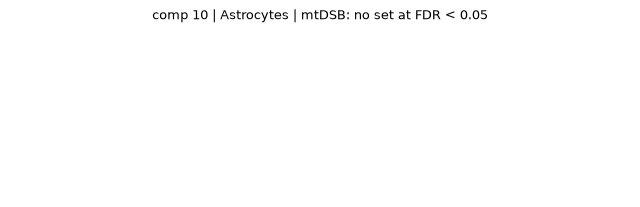

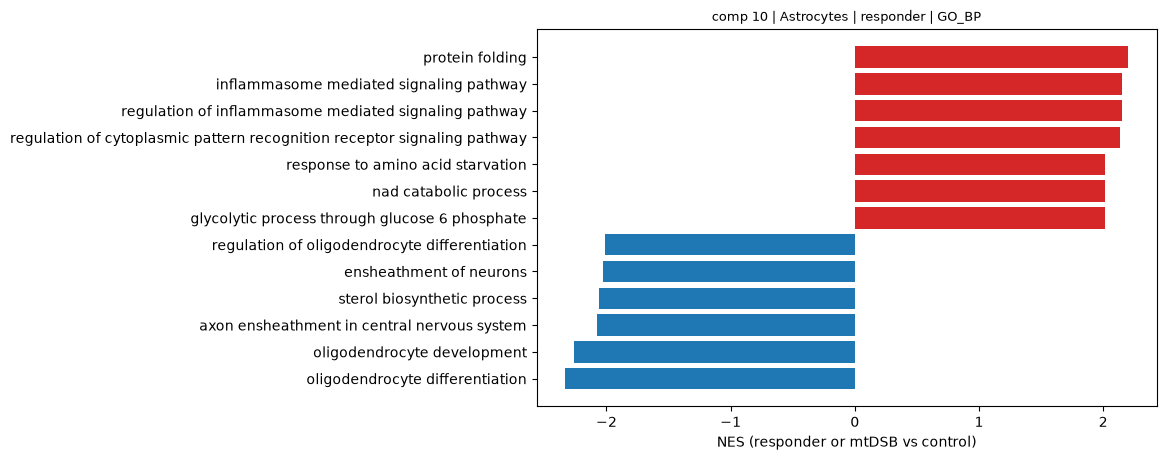

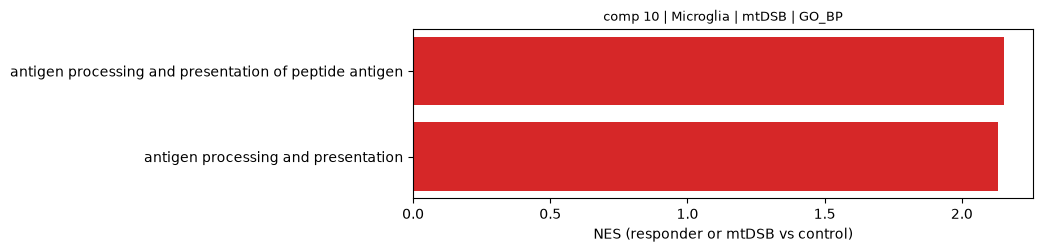

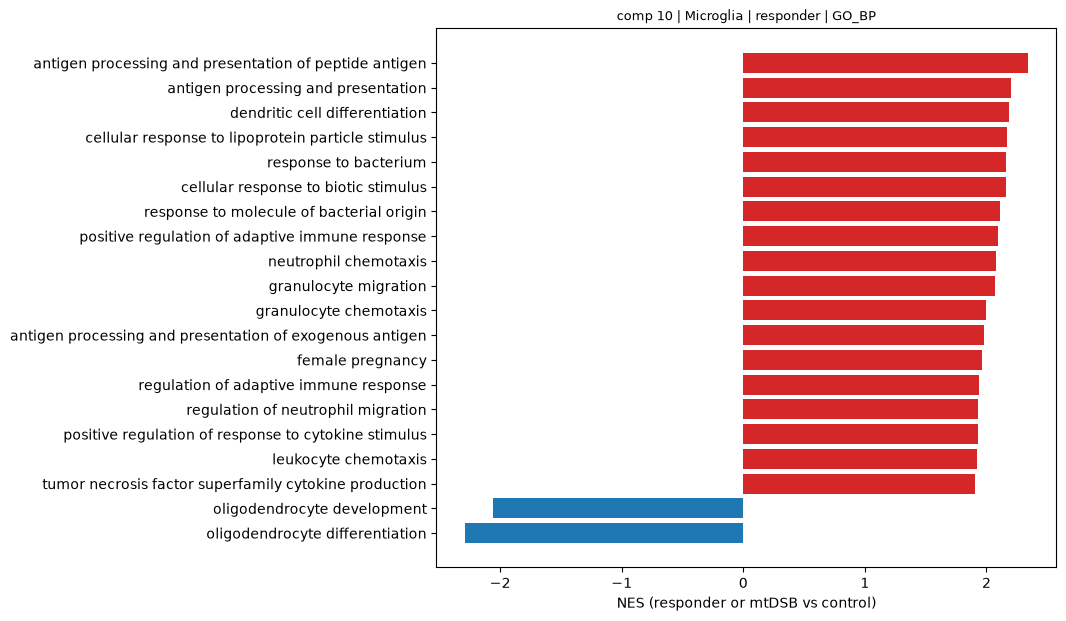

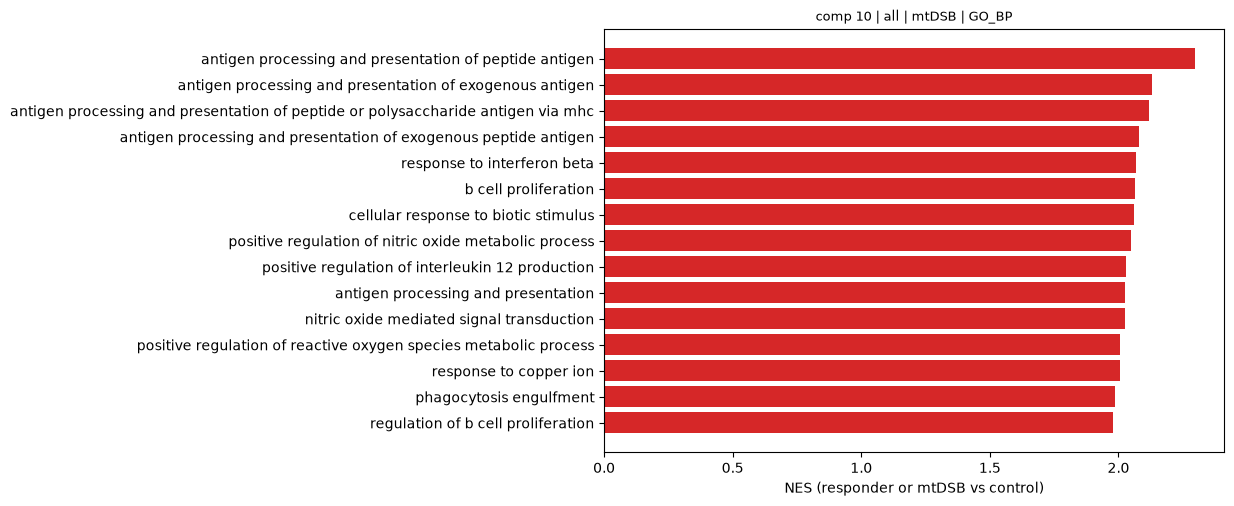

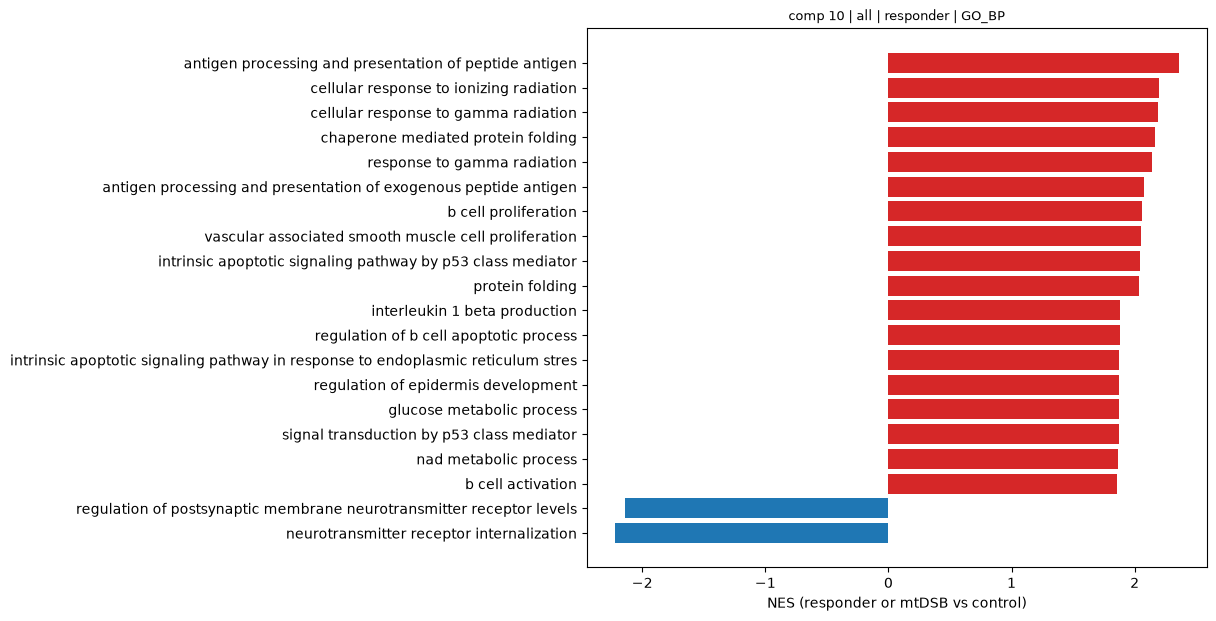

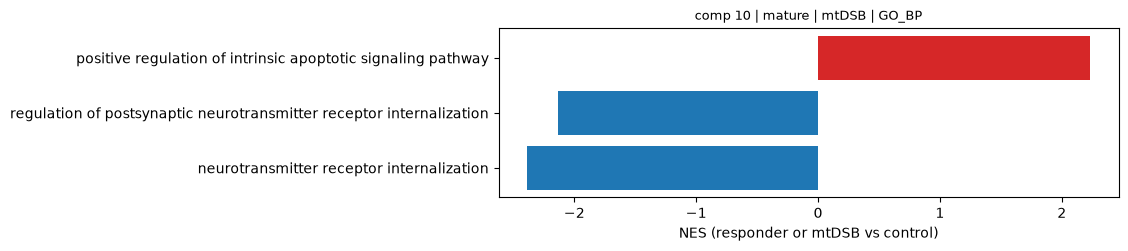

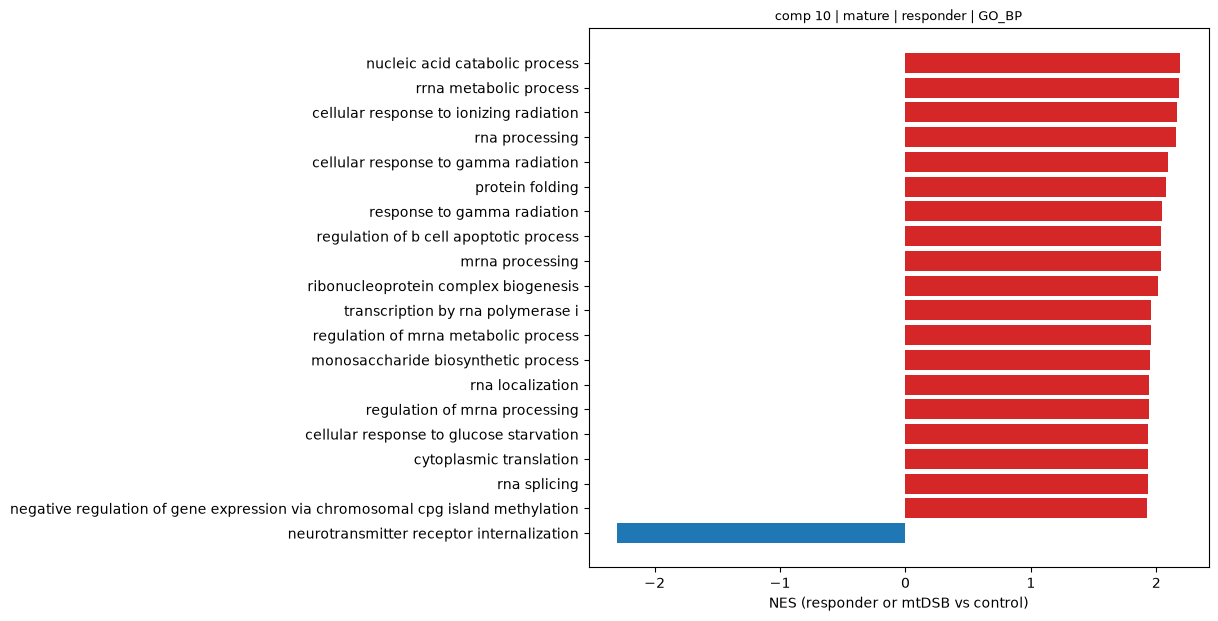

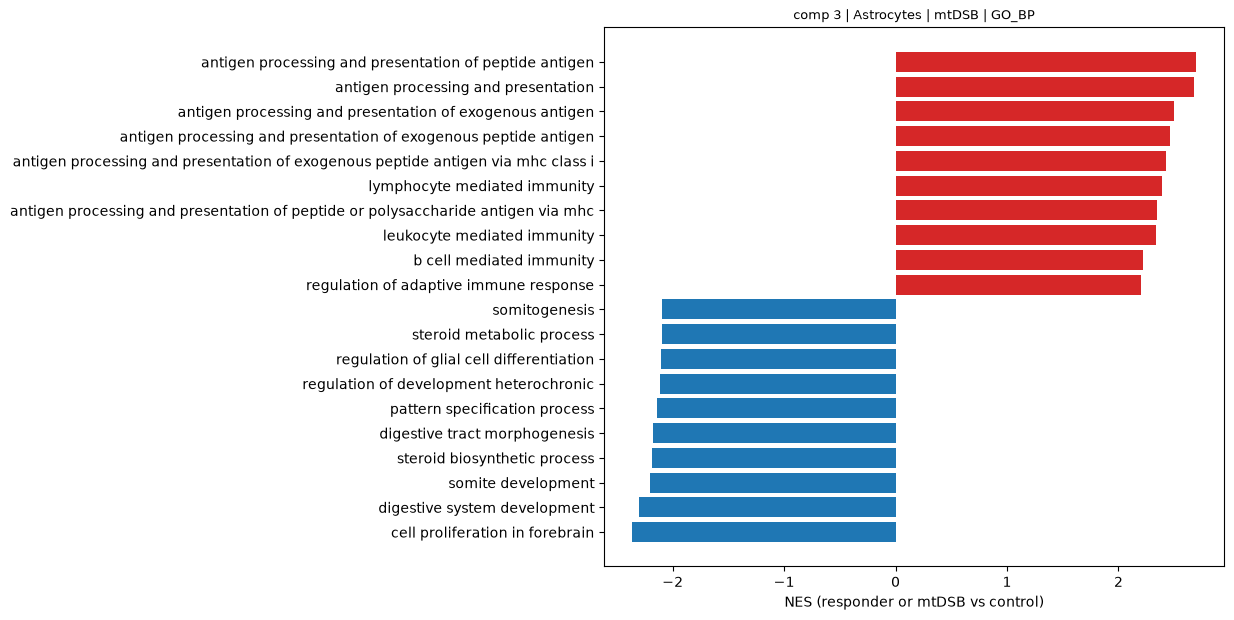

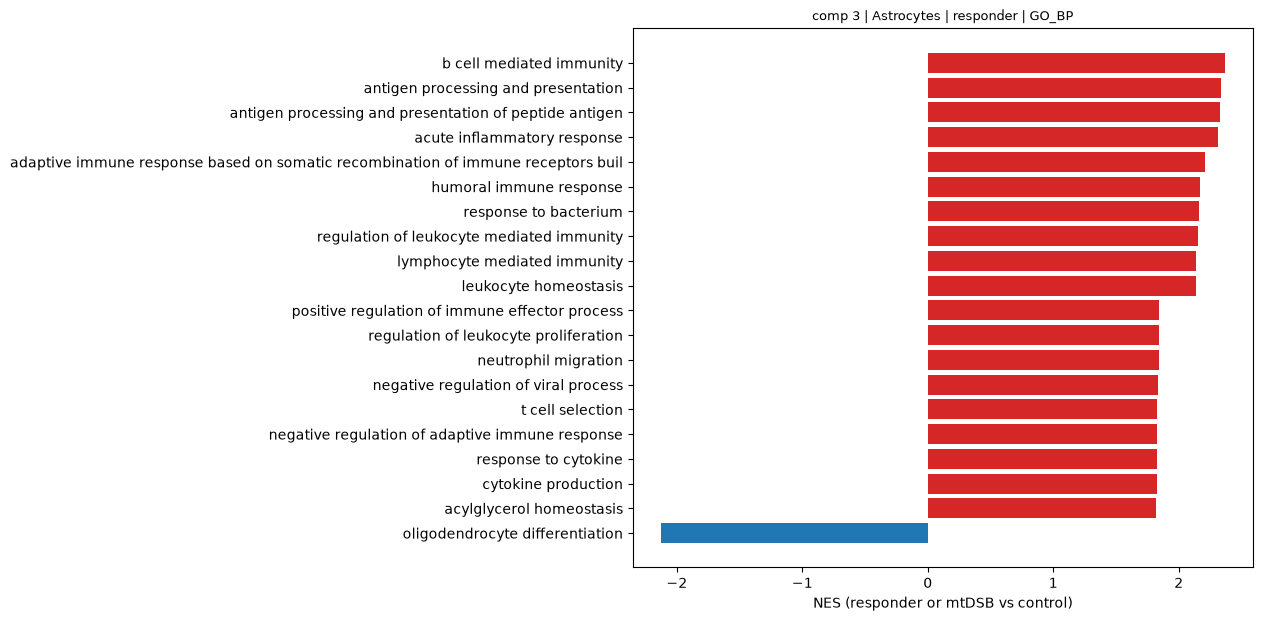

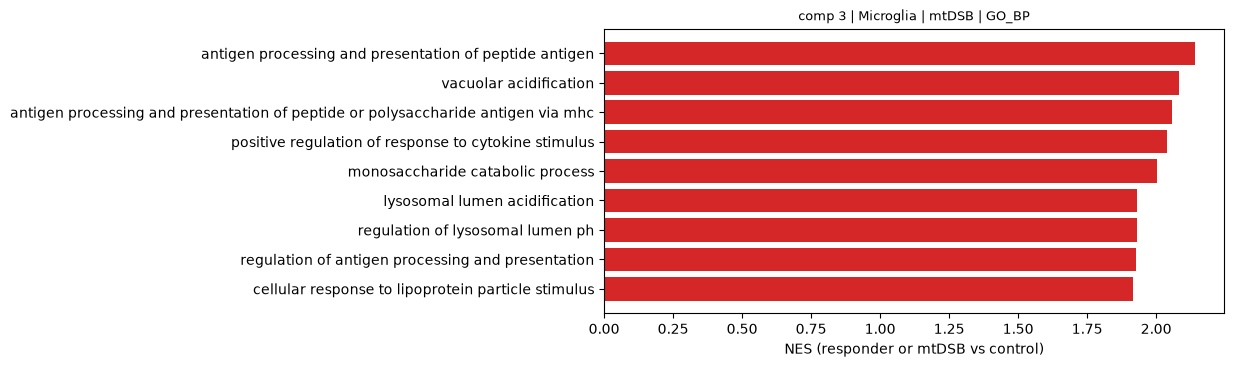

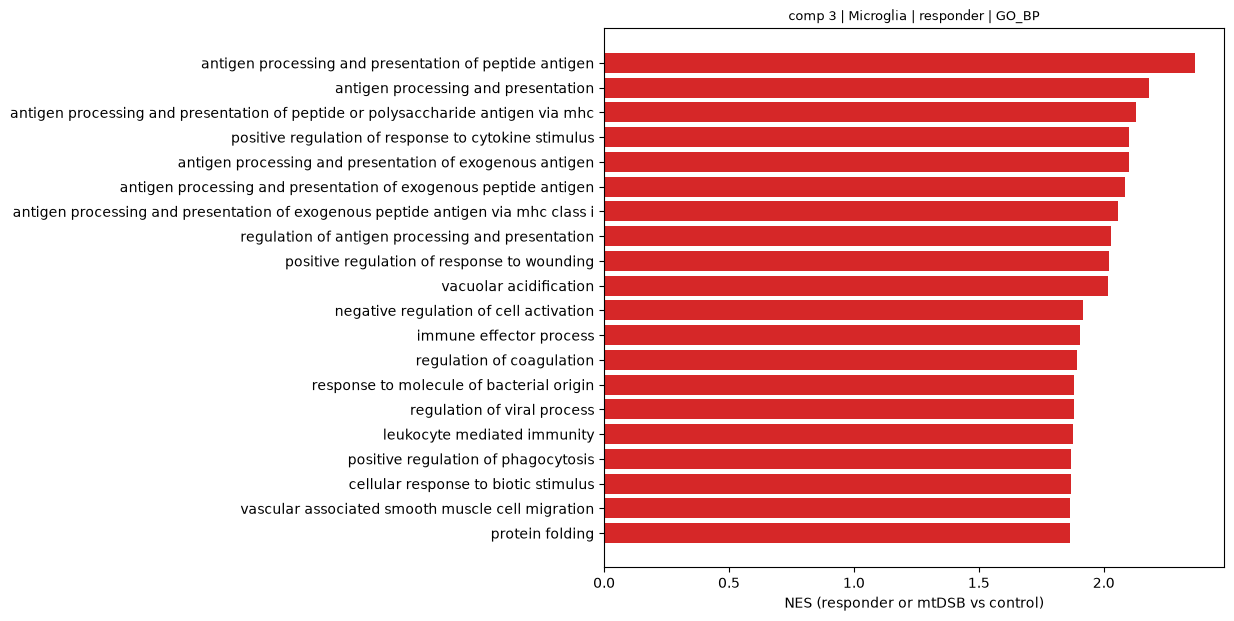

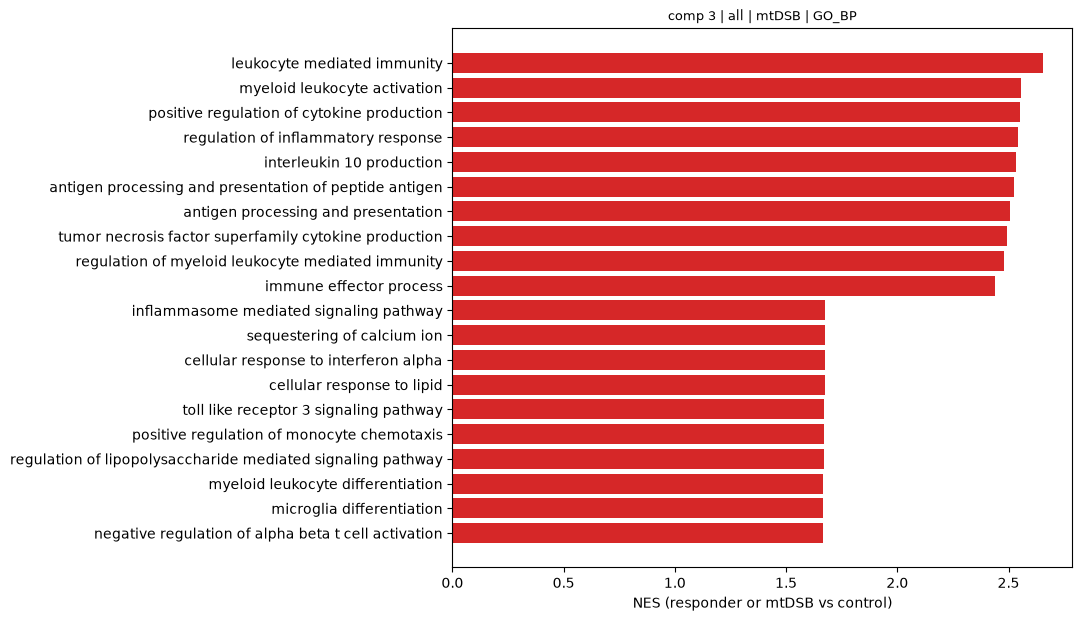

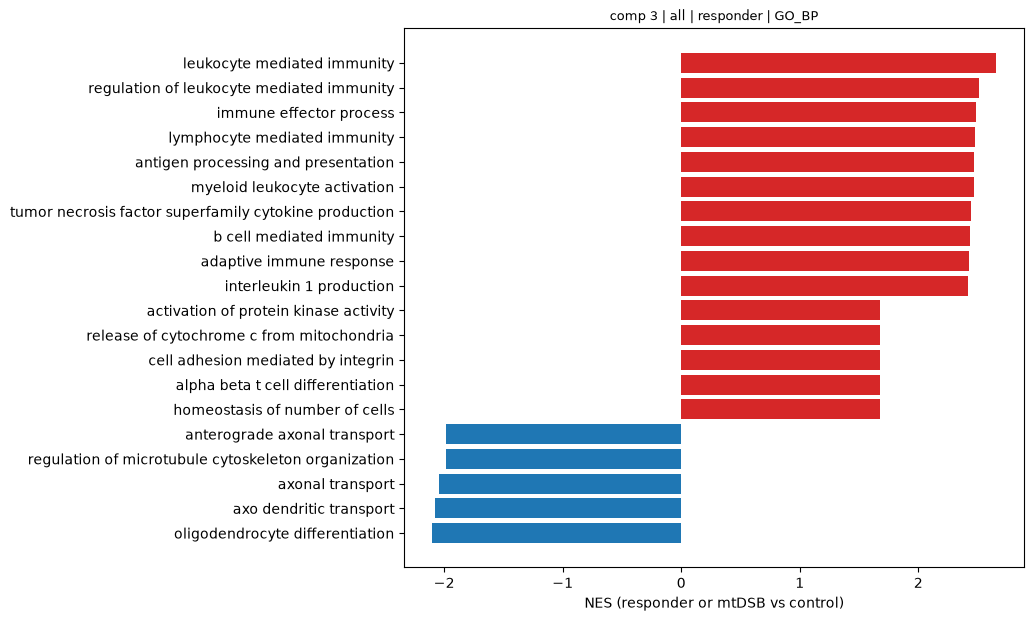

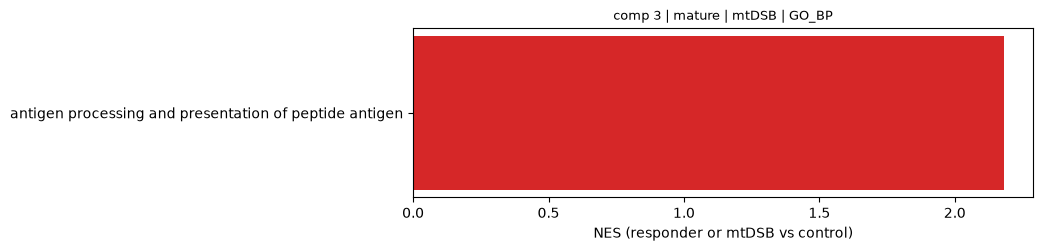

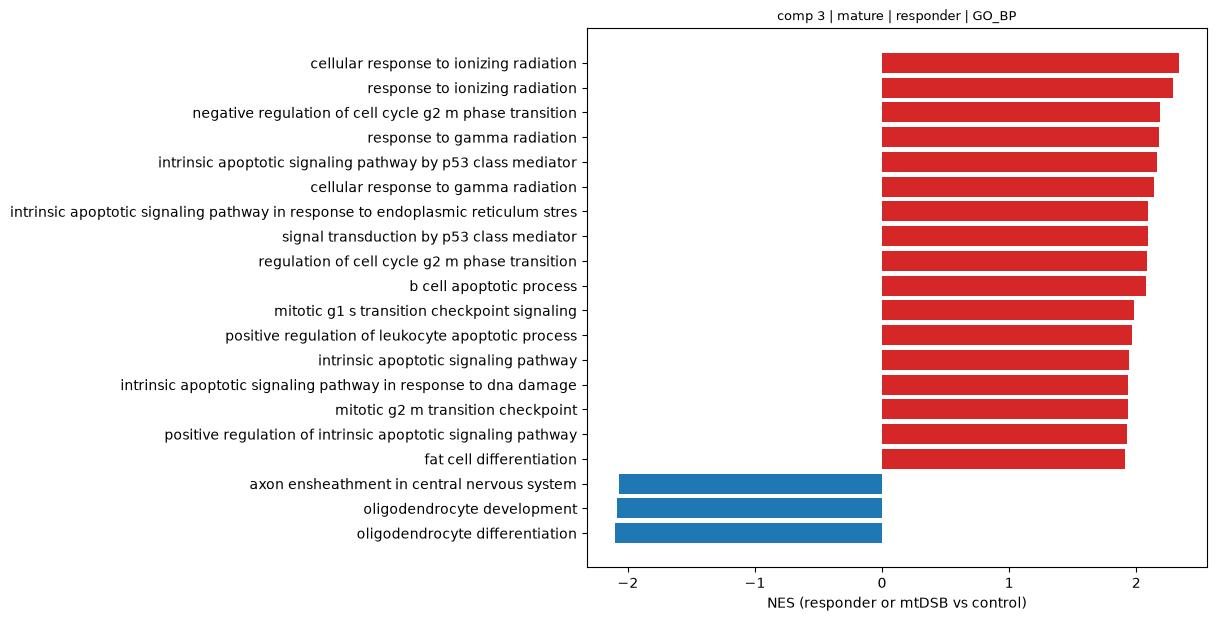

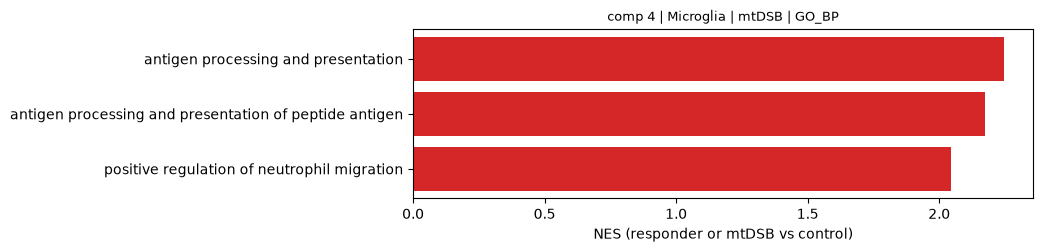

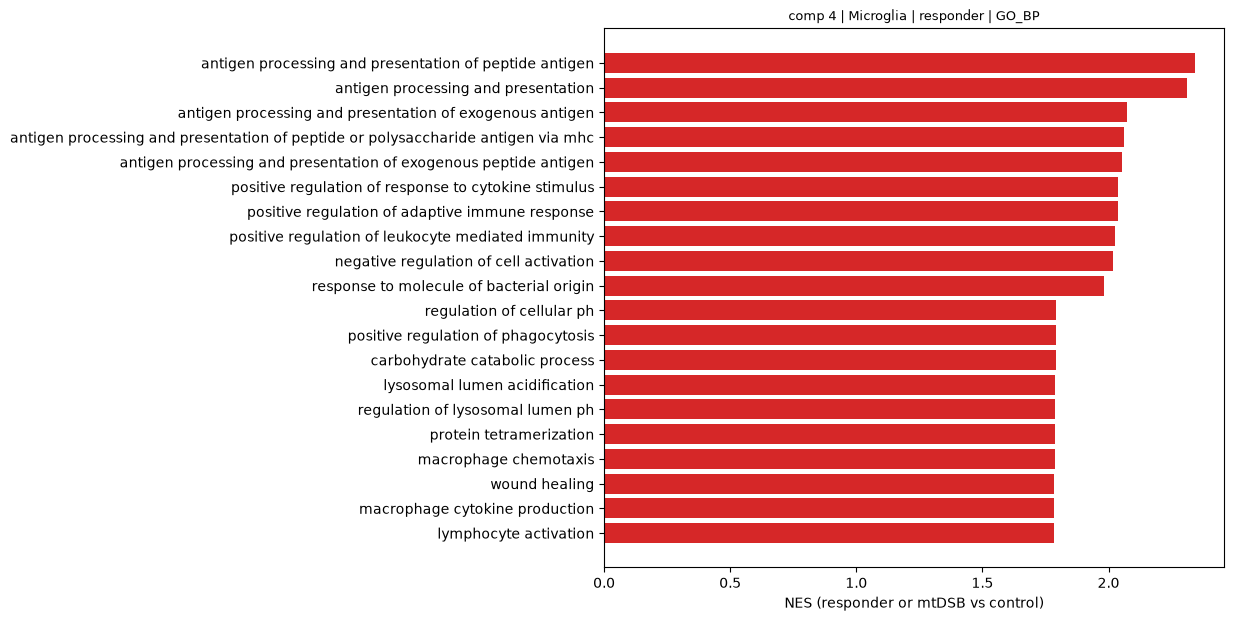

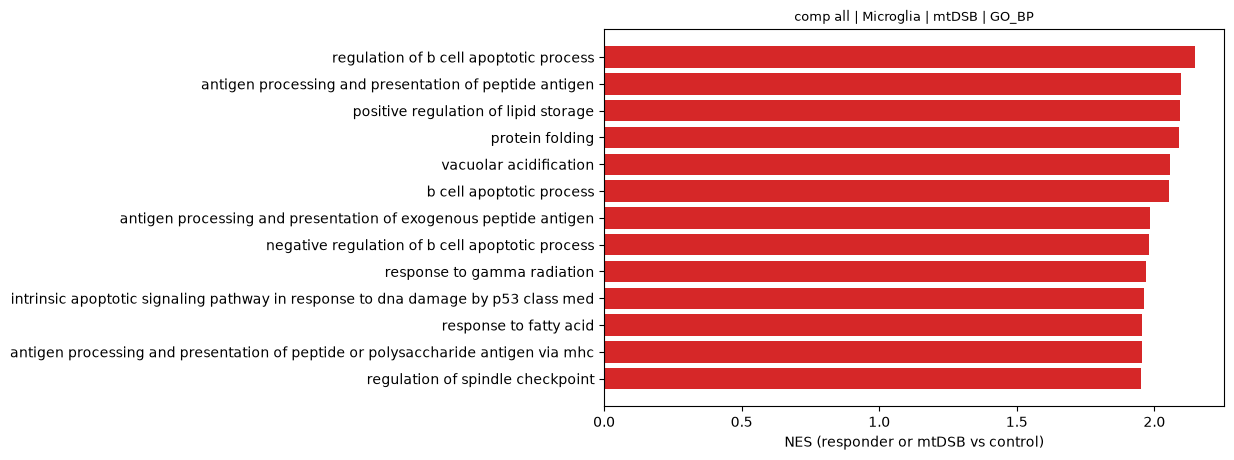

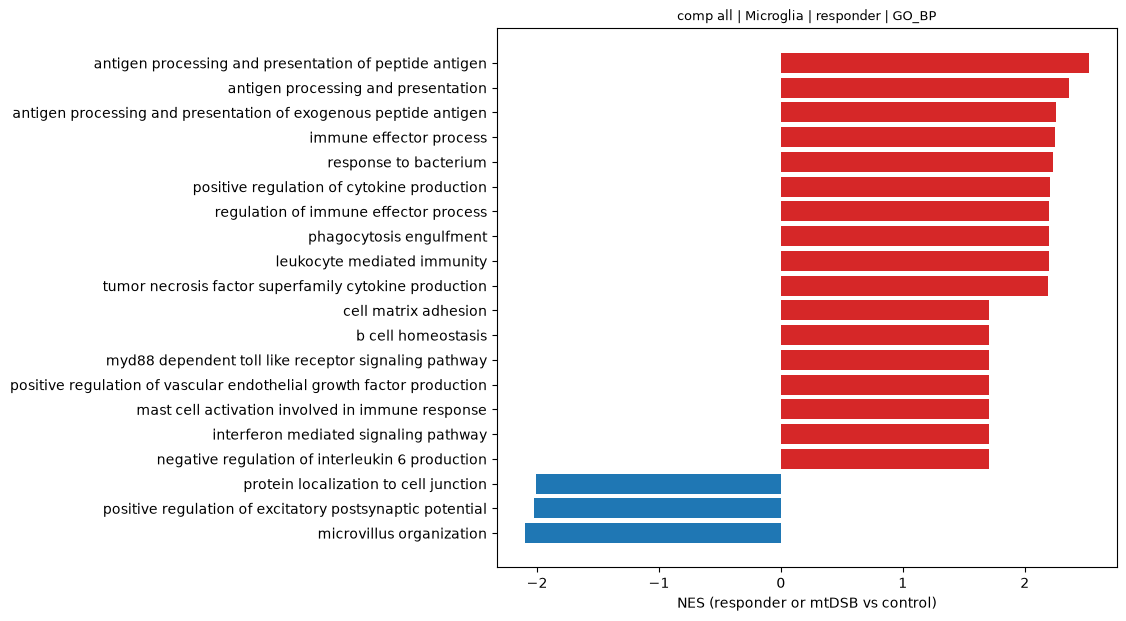

In [6]:
def plot_gsea(comp, group, comparison, lib='GO_BP', n=10, ax=None):
    r = gsea[(gsea.compartment == comp) & (gsea.group == group) & (gsea.comparison == comparison) & (gsea.library == lib)]
    r = r[r['FDR q-val'] < FDR]
    top = pd.concat([r.nlargest(n, 'NES'), r.nsmallest(n, 'NES')]).drop_duplicates('Term').sort_values('NES')
    if ax is None:
        _, ax = plt.subplots(figsize=(8, 0.3 * max(len(top), 4) + 1))
    if top.empty:
        ax.set_title(f'comp {comp} | {group} | {comparison}: no set at FDR < {FDR}', fontsize=9); ax.axis('off'); return
    labels = top['Term'].str.replace('GOBP_', '').str.replace('HALLMARK_', '').str.replace('_', ' ').str.lower().str[:80]
    ax.barh(labels, top['NES'], color=np.where(top['NES'] > 0, '#d62728', '#1f77b4'))
    ax.set_xlabel('NES (responder or mtDSB vs control)')
    ax.set_title(f'comp {comp} | {group} | {comparison} | {lib}', fontsize=9)
    return ax

for comp, group, comparison in sorted(de):
    ax = plot_gsea(comp, group, comparison)
    if ax is not None:
        plt.savefig(f'{OUT}/gsea_comp{comp}_{group}_{comparison}_GO_BP.png', dpi=150, bbox_inches='tight')
    plt.show()

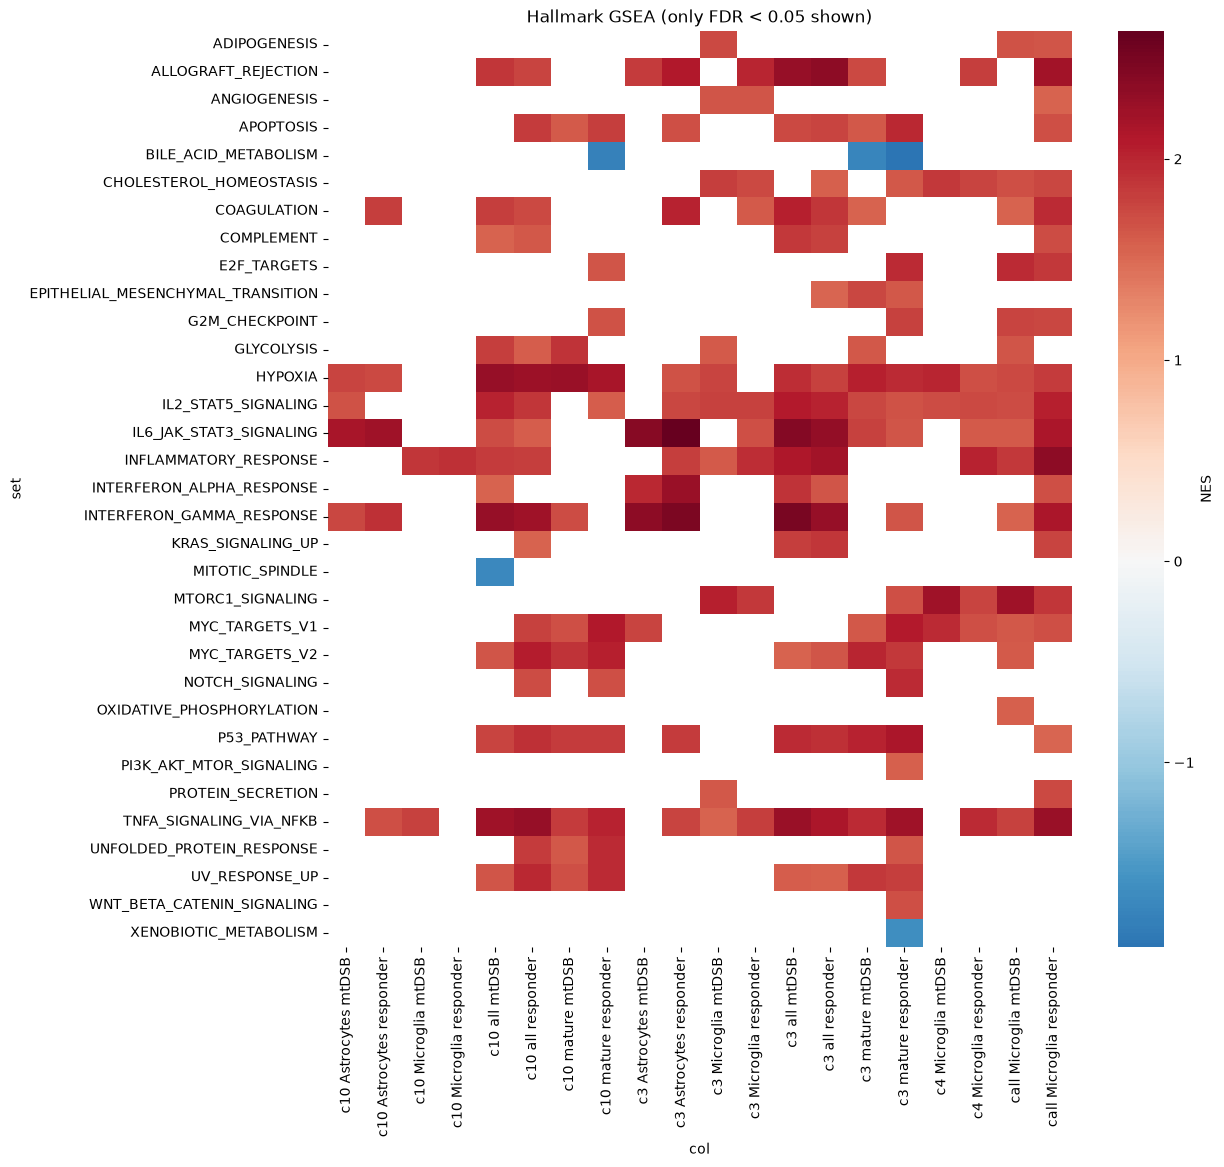

In [7]:
# Hallmark: one compact overview (NES, blank = FDR >= 0.05)
h = gsea[(gsea.library == 'Hallmark')].copy()
h['set'] = h['Term'].str.replace('HALLMARK_', '')
h['col'] = 'c' + h['compartment'] + ' ' + h['group'] + ' ' + h['comparison']
mat = h.pivot_table(index='set', columns='col', values='NES').where(
      h.pivot_table(index='set', columns='col', values='FDR q-val') < FDR)
mat = mat.dropna(how='all')
fig, ax = plt.subplots(figsize=(12, 0.3 * len(mat) + 2))
sns.heatmap(mat, cmap='RdBu_r', center=0, ax=ax, cbar_kws={'label': 'NES'})
ax.set_title(f'Hallmark GSEA (only FDR < {FDR} shown)')
fig.savefig(f'{OUT}/gsea_hallmark_overview.png', dpi=150, bbox_inches='tight')

## 4. GO heatmaps
Rows = GO:BP terms, columns = DE tables, colour = NES (all values shown), stars = FDR (* < 0.05, ** < 0.01).
Rows are the top 5 up and top 5 down terms (FDR < 0.05) of each table, after removing **redundant terms**: GO has many
near-identical terms (e.g. "response to ionizing radiation" / "... to gamma radiation"), so a term is skipped when it
shares > 50% of its genes (Jaccard) with a term already chosen. Rows are ordered by clustering.
Blank cell = term not tested in that table (fewer than 10 of its genes were tested there).

In [8]:
def pretty(term, width=70):
    t = term.replace('GOBP_', '').replace('HALLMARK_', '').replace('_', ' ').lower()
    return t if len(t) <= width else t[:width - 1] + '…'


def pick_terms(r, n, sets, jaccard=0.5):
    # top-|NES| terms of r, skipping terms that overlap a chosen one by more than `jaccard`
    kept, kept_sets = [], []
    for term in r.reindex(r['NES'].abs().sort_values(ascending=False).index)['Term']:
        genes = set(sets[term])
        if all(len(genes & k) / len(genes | k) <= jaccard for k in kept_sets):
            kept.append(term)
            kept_sets.append(genes)
        if len(kept) == n:
            break
    return kept


def table_label(comp, group, comparison):
    where = 'all comps' if comp == 'all' else f'comp {comp}'
    return f'{group} | {where} | {comparison}'


def go_heatmap(tables, n=5, title='', fname=None, lib='GO_BP'):
    g = gsea[gsea['library'] == lib]
    terms = []
    for comp, group, comparison in tables:
        r = g[(g.compartment == comp) & (g.group == group) & (g.comparison == comparison) & (g['FDR q-val'] < FDR)]
        for part in (r[r['NES'] > 0], r[r['NES'] < 0]):
            terms += [t for t in pick_terms(part, n, libraries[lib]) if t not in terms]
    if not terms:
        print('no term at FDR <', FDR); return None
    cols = [table_label(*t) for t in tables]
    sel = g[g['Term'].isin(terms)].assign(col=lambda d: [table_label(*x) for x in zip(d.compartment, d.group, d.comparison)])
    nes = sel.pivot_table(index='Term', columns='col', values='NES').reindex(index=terms, columns=cols)
    fdr = sel.pivot_table(index='Term', columns='col', values='FDR q-val').reindex(index=terms, columns=cols)
    if len(terms) > 2:
        order = leaves_list(linkage(nes.fillna(0).to_numpy(), 'average'))
        nes, fdr = nes.iloc[order], fdr.iloc[order]
    stars = fdr.map(lambda p: '**' if p < 0.01 else ('*' if p < 0.05 else ''))
    fig, ax = plt.subplots(figsize=(1.0 * len(cols) + 6, 0.28 * len(terms) + 2))
    sns.heatmap(nes.set_axis([pretty(t) for t in nes.index]), cmap='RdBu_r', center=0, annot=stars, fmt='',
                ax=ax, cbar_kws={'label': 'NES'}, linewidths=0.3, linecolor='white')
    ax.set_xlabel(''); ax.set_ylabel('')
    ax.set_title(title)
    plt.setp(ax.get_xticklabels(), rotation=45, ha='right')
    if fname:
        fig.savefig(f'{OUT}/{fname}', dpi=150, bbox_inches='tight')
    return nes, fdr

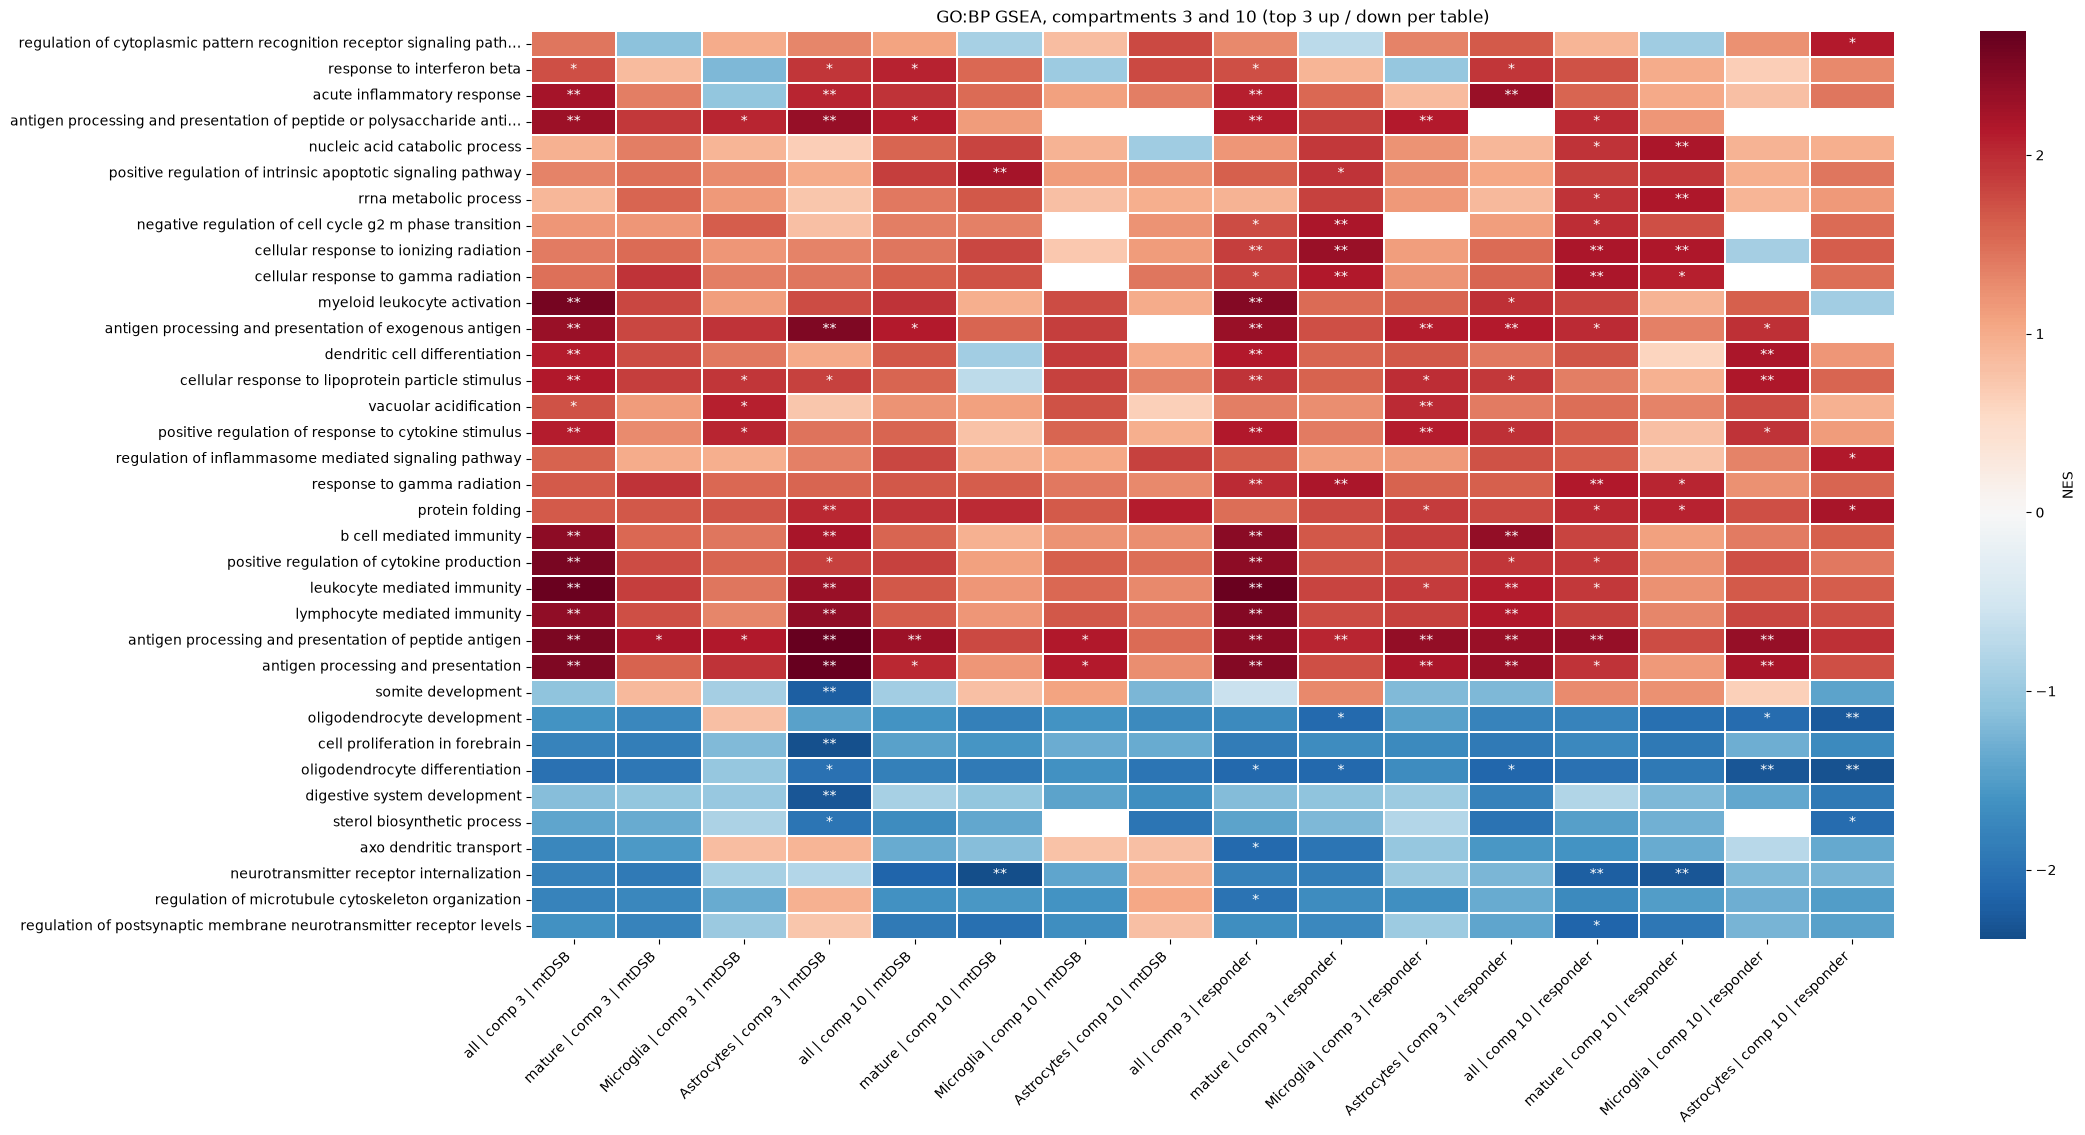

In [9]:
# overview over the compartment 3 / 10 tables (like the Hallmark overview)
tables = [(c, g, cmp) for cmp in ['mtDSB', 'responder'] for c in ['3', '10']
          for g in ['all', 'mature', 'Microglia', 'Astrocytes']]
_ = go_heatmap(tables, n=3, title='GO:BP GSEA, compartments 3 and 10 (top 3 up / down per table)',
               fname='go_heatmap_overview.png')

### Microglia: control vs mtDSB and control vs responder, whole section and per compartment
Columns: microglia over all compartments, in compartment 3 (myelinated, fibre-rich), 4 (thalamus) and 10 (corpus
callosum), for both comparisons.

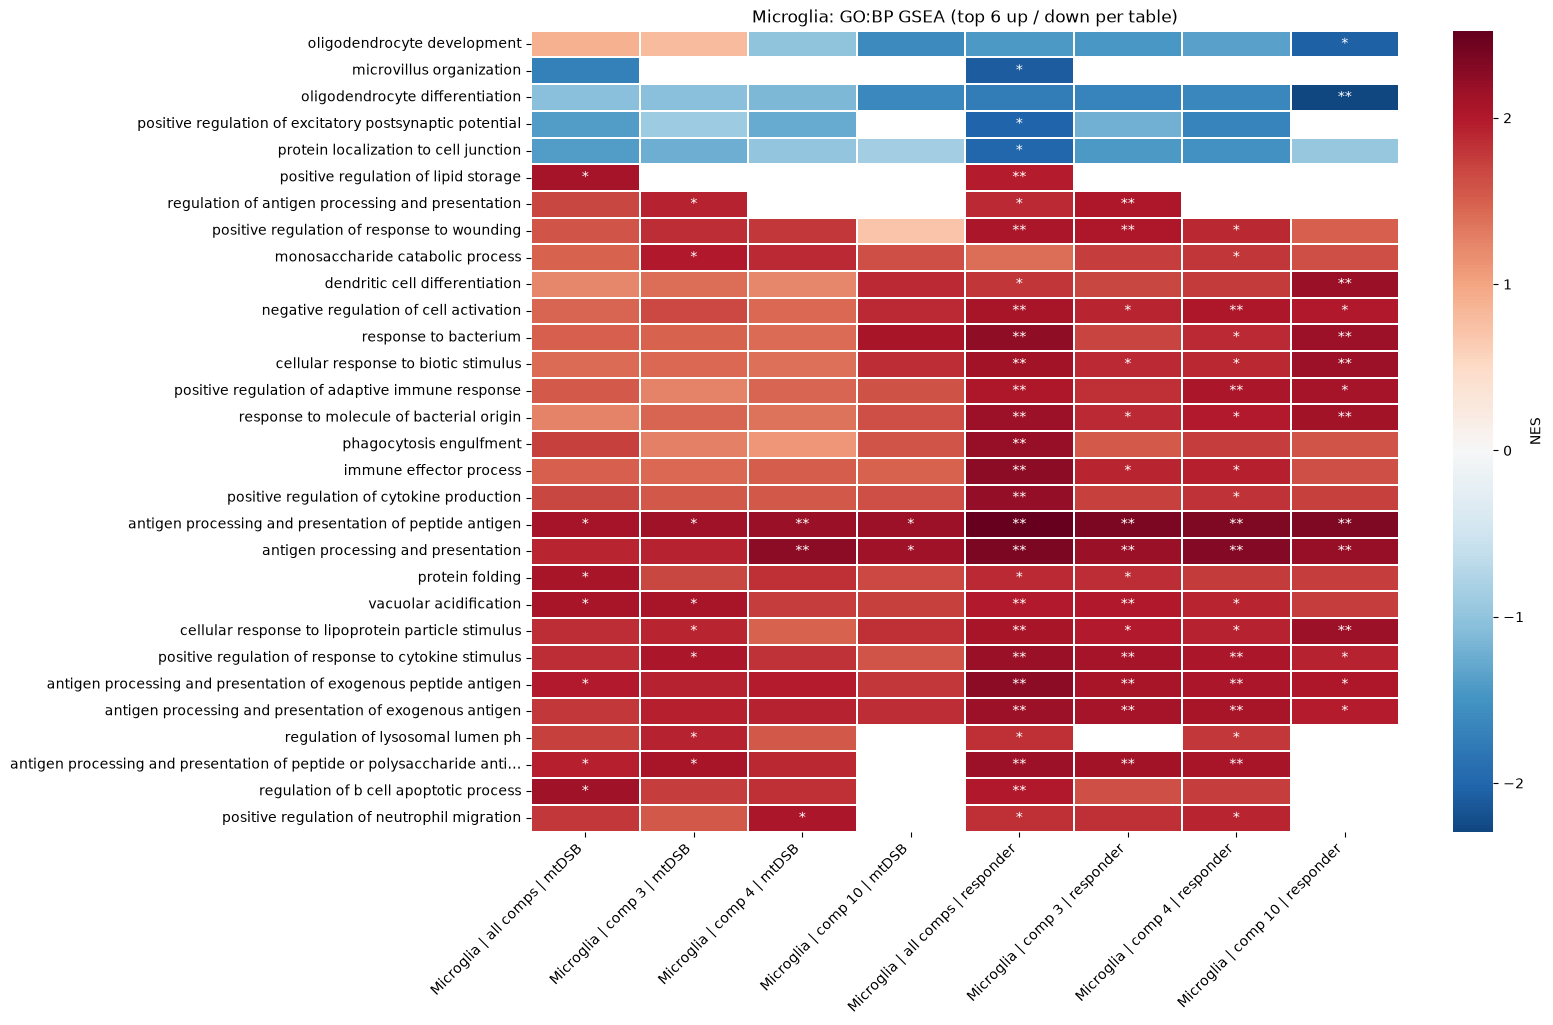

In [10]:
MG_TABLES = [(c, 'Microglia', cmp) for cmp in ['mtDSB', 'responder'] for c in ['all', '3', '4', '10']
             if (c, 'Microglia', cmp) in de]
_ = go_heatmap(MG_TABLES, n=6, title='Microglia: GO:BP GSEA (top 6 up / down per table)', fname='go_heatmap_microglia.png')

In [11]:
# top non-redundant terms per microglia table, with leading-edge genes
rows = []
g = gsea[gsea['library'] == 'GO_BP']
for comp, group, comparison in MG_TABLES:
    r = g[(g.compartment == comp) & (g.group == group) & (g.comparison == comparison) & (g['FDR q-val'] < FDR)]
    for direction, part in [('up', r[r['NES'] > 0]), ('down', r[r['NES'] < 0])]:
        for term in pick_terms(part, 10, libraries['GO_BP']):
            x = part[part['Term'] == term].iloc[0]
            rows.append({'table': table_label(comp, group, comparison), 'direction': direction, 'term': pretty(term, 90),
                         'NES': round(x['NES'], 2), 'FDR': x['FDR q-val'],
                         'leading edge (first 12)': ', '.join(str(x['Lead_genes']).split(';')[:12])})
mg_terms = pd.DataFrame(rows)
mg_terms.to_csv(f'{OUT}/gsea_microglia_top_terms.csv', index=False)
with pd.option_context('display.max_rows', 300, 'display.max_colwidth', 120):
    display(mg_terms)

,table,direction,term,NES,FDR,leading edge (first 12)
0,Microglia | all comps | mtDSB,up,regulation of b cell apoptotic process,2.15,0.013690,"Cd74, Cd44, Pdcd1, Myc, Irs2, Aurkb, Bax, Bcl2a1a"
1,Microglia | all comps | mtDSB,up,antigen processing and presentation of peptide antigen,2.10,0.018579,"Cd74, H2-Aa, H2-Ab1, H2-Eb1, H2-D1, Ctsl, H2-K1, Fcgr2b, Slc11a1, B2m, Fcgr3, Tap1"
2,Microglia | all comps | mtDSB,up,positive regulation of lipid storage,2.09,0.014342,"Msr1, Lpl, Plin2, Cd36, C3"
3,Microglia | all comps | mtDSB,up,protein folding,2.09,0.012468,"Cd74, Hspd1, Grn, Cct8, Fkbp5, Hspa9, Tcp1, B2m, P4hb, Cdc37, Hspa5, Cct5"
4,Microglia | all comps | mtDSB,up,vacuolar acidification,2.06,0.018579,"Atp6v0d2, Grn, Lamp1, Cln3, Creg1, Slc11a1, Atp6v1b2, Clic4, Lamp2, Ppt1"
5,Microglia | all comps | mtDSB,up,antigen processing and presentation of exogenous peptide antigen,1.98,0.044981,"Cd74, H2-Aa, H2-Ab1, H2-Eb1, H2-K1, Fcgr2b, B2m, Fcgr3, H2-DMa"
6,Microglia | all comps | mtDSB,up,response to gamma radiation,1.97,0.046393,"Cdkn1a, Myc, Chek2, Men1, Bax, Xrcc6, Ercc6, Ptprc, Apobec1, Bcl2l1, Zmpste24, Egr1"
7,Microglia | all comps | mtDSB,up,intrinsic apoptotic signaling pathway in response to dna damage by p53 class mediator,1.96,0.046546,"Cdkn1a, Cd74, Ifi204, Cd44, Chek2, Ddit4, Msh2, Pmaip1"
8,Microglia | all comps | mtDSB,up,response to fatty acid,1.95,0.047826,"Lpl, Hmox1, Cd36, Tlr2, Tlr4, Trpv4"
9,Microglia | all comps | mtDSB,up,regulation of spindle checkpoint,1.95,0.042649,"Ccnb1, Knl1, Aurkb, Aurka, Cdca8, Birc5, Mad2l1, Gen1"


## 5. ORA of the DE genes (complement)
Only for tables with ≥ 20 genes at padj < 0.05 in a direction. Universe = tested genes of that table.

In [12]:
ora = []
for (comp, group, comparison), res in de.items():
    universe = set(res.index)
    for direction, sel in [('up', res.log2FoldChange > 0), ('down', res.log2FoldChange < 0)]:
        genes = res.index[(res.padj < 0.05) & sel].tolist()
        if len(genes) < 20:
            continue
        for lib, sets in libraries.items():
            e = gp.enrich(gene_list=genes, gene_sets=restrict(sets, universe), background=sorted(universe),
                          outdir=None, cutoff=1, no_plot=True, verbose=False)
            ora.append(e.res2d.assign(compartment=comp, group=group, comparison=comparison,
                                      direction=direction, library=lib, n_genes=len(genes)))
ora = pd.concat(ora, ignore_index=True).sort_values('P-value')
ora.to_csv(f'{OUT}/ora_all.csv', index=False)
(ora[ora['Adjusted P-value'] < FDR]
    .groupby(['comparison', 'compartment', 'group', 'direction', 'library']).head(5)
    [['comparison', 'compartment', 'group', 'direction', 'library', 'Term', 'Overlap', 'Adjusted P-value', 'Genes']])

,comparison,compartment,group,direction,library,Term,Overlap,Adjusted P-value,Genes
15924,responder,3,all,up,GO_BP,GOBP_IMMUNE_EFFECTOR_PROCESS,67/272,8.952700e-21,Ptafr;Cd180;Lyn;Casp1;Cd86;Tlr7;Ccl2;Tlr9;Ndst...
16014,responder,3,all,up,GO_BP,GOBP_LEUKOCYTE_MEDIATED_IMMUNITY,51/165,4.757389e-20,Ptafr;Lyn;Ccl2;Tlr9;Ndst2;Fgr;Tap1;Lag3;B2m;H2...
15264,responder,3,all,up,GO_BP,GOBP_ADAPTIVE_IMMUNE_RESPONSE,51/187,1.773016e-17,Lyn;H2-Aa;Cd86;Tap1;Tnfaip3;Lag3;B2m;H2-Ab1;St...
16764,responder,3,all,up,GO_BP,GOBP_POSITIVE_REGULATION_OF_CYTOKINE_PRODUCTION,57/240,8.160609e-17,Ptafr;Casp1;Tlr7;Ccl2;Tlr9;Fgr;Tnfrsf1a;B2m;Po...
15324,responder,3,all,up,GO_BP,GOBP_ANTIGEN_PROCESSING_AND_PRESENTATION_OF_PE...,18/22,6.413057e-16,H2-Aa;Traf6;Trem2;Fcgr1;Ctss;H2-D1;H2-K1;H2-Eb...
...,...,...,...,...,...,...,...,...,...
10052,responder,3,Astrocytes,up,Hallmark,HALLMARK_COAGULATION,4/29,8.354744e-03,Serping1;A2m;Cd9;Capn2
4155,responder,10,all,down,Hallmark,HALLMARK_MTORC1_SIGNALING,7/73,3.702254e-02,Psat1;Idi1;Ldlr;Acaca;Idh1;Acly;Vldlr
10047,responder,3,Astrocytes,up,Hallmark,HALLMARK_ALLOGRAFT_REJECTION,5/53,9.055486e-03,Flna;B2m;Cd74;Fcgr2b;Csf1
4138,responder,10,all,down,Hallmark,HALLMARK_CHOLESTEROL_HOMEOSTASIS,4/24,3.702254e-02,Ldlr;Srebf2;Fasn;Idi1


## 6. Reading the results
- Look for agreement between GSEA and ORA and between compartments 3 and 10.
- Compare responder OL terms with the CM driver genes (finding 2): stress / p53-like survival and MHC-I up, myelination
  and OL differentiation down.
- A first test run on `comp 3 | mature OL | responder vs control` gave DNA-damage / p53 terms up (cellular response to
  ionizing radiation, p53-mediated apoptosis, ER-stress apoptosis; FDR < 0.005) and myelination terms down (axon
  ensheathment in CNS, OL differentiation; FDR ≈ 0.02–0.03). This fits double-strand breaks and the CM findings.
- "All cells" tables mix composition and expression: a term there can come from more microglia or DA-OLs in the
  compartment rather than from regulation in any cell type.
- **Spill-over from neighbouring cells**: segmented "microglia" contain some transcripts of the cells around them. Terms
  carried by other cell types' genes are spill-over, not microglial regulation: for example "oligodendrocyte
  differentiation" down in microglia of compartment 10 (leading edge Mal, Cnp, Mag, Opalin: OL myelin genes that drop in
  responders), or "excitatory postsynaptic potential" down (Dlg4, Grin1, Camk2a: neuronal). Always check the leading-edge
  genes.

**Microglia, test run of 2026-10-21 (re-check after re-running):**
- **The same programme appears everywhere it is tested**: antigen presentation (MHC-II Cd74, H2-Aa/Ab1/Eb1 and MHC-I
  H2-D1, H2-K1, B2m), lysosome / vacuolar acidification (Lamp1/2, Grn, Atp6v), lipid handling (Lpl, Cd36, Cd9, Trem2,
  Abca1: "response to lipoprotein particle") and cytokine-response regulation (Axl, Tlr2, Csf1). Together these form a
  DAM / MHC-high profile, consistent with the DE (Cst7, Cd74, Lpl) and with CM finding 5.
- **Responders vs controls**: strong in all four scopes (whole section, compartments 3, 4 and 10; many terms FDR < 0.01).
- **mtDSB vs control**: the same terms, weaker (FDR 0.01–0.05), mostly antigen presentation; diluted by the non-responders.
- Whole section, mtDSB only: also DNA-damage / p53 terms (Cdkn1a, Chek2, Bax: "response to gamma radiation"), protein
  folding (Hspd1, Hspa9, Hspa5) and lipid storage.
- Compartment 10 shows the microglial activation here, while the Tangram states of notebook 04 did not. Pseudobulk GSEA
  picks up small coordinated shifts in many genes, whereas the atlas states are coarse and soft. The DE result is the more
  sensitive readout for this question.